In [4]:
import os
from pycirclize import Circos
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.transforms import Affine2D
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import pandas as pd
from Bio import SeqIO

In [5]:
# Function to parse a .gd file and extract SNPs, deletions, and insertions
def parse_gd_file(file_path):
    snps, deletions, insertions = [], [], []
    with open(file_path, 'r') as f:
        for line in f:
            if line.startswith("SNP"):
                cols = line.strip().split("\t")
                snps.append(int(cols[4]))  # SNP positions
            elif line.startswith("DEL"):
                cols = line.strip().split("\t")
                deletions.append((int(cols[4]), int(cols[4])+int(cols[5])))  # Deletion start and end
            elif line.startswith("INS"):
                cols = line.strip().split("\t")
                insertions.append((int(cols[4]), len(cols[5])))  # Insertion start and size
            elif line.startswith("MC"):
                cols = line.strip().split("\t")
                deletions.append(((int(cols[4])+int(cols[6])), int(cols[5])+int(cols[7]))) # Deletion start and end
    return snps, deletions, insertions

In [6]:
# 1. Where you put the GitHub directory (your parent workspace folder)
base_dir = Path(r'C:\Users\jmf7ak\OneDrive - University of Virginia\25_SPRING\Evolution_paper')

# 2. The GitHub repository name
repo_name = 'media_evolution_paper'

# 3. Combine them to get your final gd_dir path
gd_dir = base_dir / repo_name / 'data' / 'gd_files'

print(gd_dir)

In [7]:
# Genome length
genome_length =  6537648

gbk_file = base_dir / repo_name / 'data' / "PA14_GBK.gbk"

In [8]:
def parse_gbk_for_genes(gbk_file):
    gene_map = []
    with open(gbk_file, "r") as file:
        for record in SeqIO.parse(file, "genbank"):
            for feature in record.features:
                if feature.type == "gene":
                    # Check for gene name first; if absent or None, use locus_tag
                    gene_name = feature.qualifiers.get("gene", [None])[0]
                    if not gene_name:
                        gene_name = feature.qualifiers.get("locus_tag", ["Intergenic"])[0]
                    gene_map.append((int(feature.location.start), int(feature.location.end), gene_name))
    return gene_map
    
def label_mutations(snps, deletions, gene_map):
    gene_names = []
    for snp in snps:
        matched_gene = "Intergenic"
        for start, end, gene_name in gene_map:
            if start <= snp <= end:
                matched_gene = gene_name
                break
        gene_names.append((snp, matched_gene))
    return gene_names

In [9]:
'''
radius_map = {   
'AE_P1_S13_subtracted.gd' : 86.5,
'AE_P2_S14_subtracted.gd' : 88,
'AE_P3_S15_subtracted.gd' : 89.5,
'AE_P4_S16_subtracted.gd' : 91,
    
'AN_P2_S29_subtracted.gd' : 94,
'AN_P3_S30_subtracted.gd' : 95.5,
'AN_P4_S31_subtracted.gd' : 97,
'AN_P6_S32_subtracted.gd' : 98.5,
    
'AE_T1_S17_subtracted.gd' : 69.5,
'AE_T2_S18_subtracted.gd' : 71,
'AE_T3_S19_subtracted.gd' : 72.5,
'AE_T5_S20_subtracted.gd' : 74,

'AN_T1_S33_subtracted.gd' : 77,
'AN_T2_S34_subtracted.gd' : 78.5,
'AN_T3_S35_subtracted.gd' : 80,
'AN_T4_S36_subtracted.gd' : 81.5,

'AE_C1_S21_subtracted.gd' : 52.5,
'AE_C2_S22_subtracted.gd' : 54,
'AE_C3_S23_subtracted.gd' : 55.5,
'AE_C6_S24_subtracted.gd' : 57,
    
'AN_C1_S37_subtracted.gd' : 60,
'AN_C2_S38_subtracted.gd' : 61.5,
'AN_C3_S39_subtracted.gd' : 63,
'AN_C4_S40_subtracted.gd' : 64.5,
    
'AE_N1_S25_subtracted.gd' : 35.5,
'AE_N2_S26_subtracted.gd' : 37,
'AE_N3_S27_subtracted.gd' : 38.5,
'AE_N4_S28_subtracted.gd' : 40, #this is the one with the misname from seqcenter
    
'AN_N1_S41_subtracted.gd' : 43,
'AN_N2_S42_subtracted.gd' : 44.5,
'AN_N3_S43_subtracted.gd' : 46,
'AN_N4_S44_subtracted.gd' : 47.5,
}
'''
radius_map = {   
'AE_P1_S13_subtracted.gd' : 86.5,
'AE_P2_S14_subtracted.gd' : 88,
'AE_P3_S15_subtracted.gd' : 89.5,
'AE_P4_S16_subtracted.gd' : 91,
    
'AN_P2_S29_subtracted.gd' : 94,
'AN_P3_S30_subtracted.gd' : 95.5,
'AN_P4_S31_subtracted.gd' : 97,
'AN_P6_S32_subtracted.gd' : 98.5,
    
'AE_T1_S17_subtracted.gd' : 69.5,
'AE_T2_S18_subtracted.gd' : 71,
'AE_T3_S19_subtracted.gd' : 72.5,

'AE_T5_S20_subtracted.gd' : 74,

'AN_T1_S33_subtracted.gd' : 77,
'AN_T2_S34_subtracted.gd' : 78.5,
'AN_T3_S35_subtracted.gd' : 80,
'AN_T4_S36_subtracted.gd' : 81.5,

'AE_C1_S21_subtracted.gd' : 52.5,
'AE_C2_S22_subtracted.gd' : 54,
'AE_C3_S23_subtracted.gd' : 55.5,
'AE_C6_S24_subtracted.gd' : 57,
    
'AN_C1_S37_subtracted.gd' : 60,
'AN_C2_S38_subtracted.gd' : 61.5,
'AN_C3_S39_subtracted.gd' : 63,
'AN_C4_S40_subtracted.gd' : 64.5,
    
'AE_N1_S25_subtracted.gd' : 35.5,
'AE_N2_S26_subtracted.gd' : 37,
'AE_N3_S27_subtracted.gd' : 38.5,
'AE_N4_S28_subtracted.gd' : 40,#this is the one with the misname from seqcenter
    
'AN_N1_S41_subtracted.gd' : 43,
'AN_N2_S42_subtracted.gd' : 44.5,
'AN_N3_S43_subtracted.gd' : 46,
'AN_N4_S44_subtracted.gd' : 47.5,
}

AE_C1_S21_subtracted.gd
AE_C2_S22_subtracted.gd
AE_C3_S23_subtracted.gd
AE_C6_S24_subtracted.gd
AE_N1_S25_subtracted.gd
AE_N2_S26_subtracted.gd
AE_N3_S27_subtracted.gd
AE_N4_S28_subtracted.gd
AE_P1_S13_subtracted.gd
AE_P2_S14_subtracted.gd
AE_P3_S15_subtracted.gd
AE_P4_S16_subtracted.gd
AE_T1_S17_subtracted.gd
AE_T2_S18_subtracted.gd
AE_T3_S19_subtracted.gd
AE_T5_S20_subtracted.gd
AN_C1_S37_subtracted.gd
AN_C2_S38_subtracted.gd
AN_C3_S39_subtracted.gd
AN_C4_S40_subtracted.gd
AN_N1_S41_subtracted.gd
AN_N2_S42_subtracted.gd
AN_N3_S43_subtracted.gd
AN_N4_S44_subtracted.gd
AN_P2_S29_subtracted.gd
AN_P3_S30_subtracted.gd
AN_P4_S31_subtracted.gd
AN_P6_S32_subtracted.gd
AN_T1_S33_subtracted.gd
AN_T2_S34_subtracted.gd
AN_T3_S35_subtracted.gd
AN_T4_S36_subtracted.gd
Annotated 'gyrB' at coordinate 5484.5
Annotated 'ptsP' at coordinate 393909.0
Annotated 'mexR' at coordinate 486278.0
Annotated 'fusA1' at coordinate 756724.5
Annotated 'mpl' at coordinate 1027083.0
Annotated 'PA14_12490' at coordin

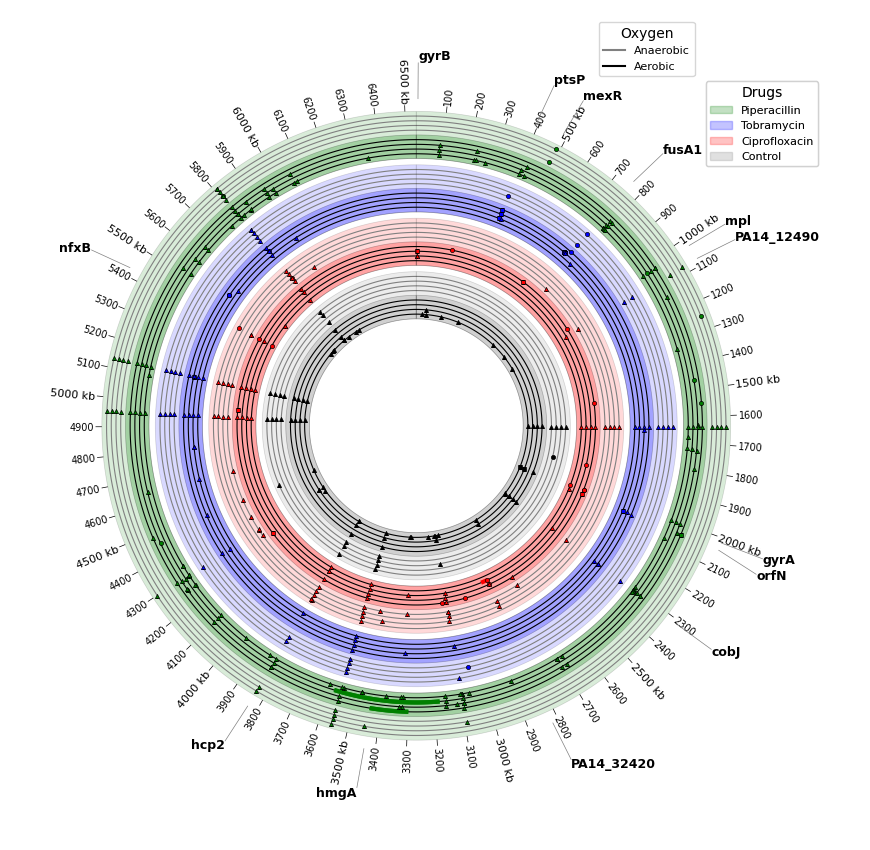

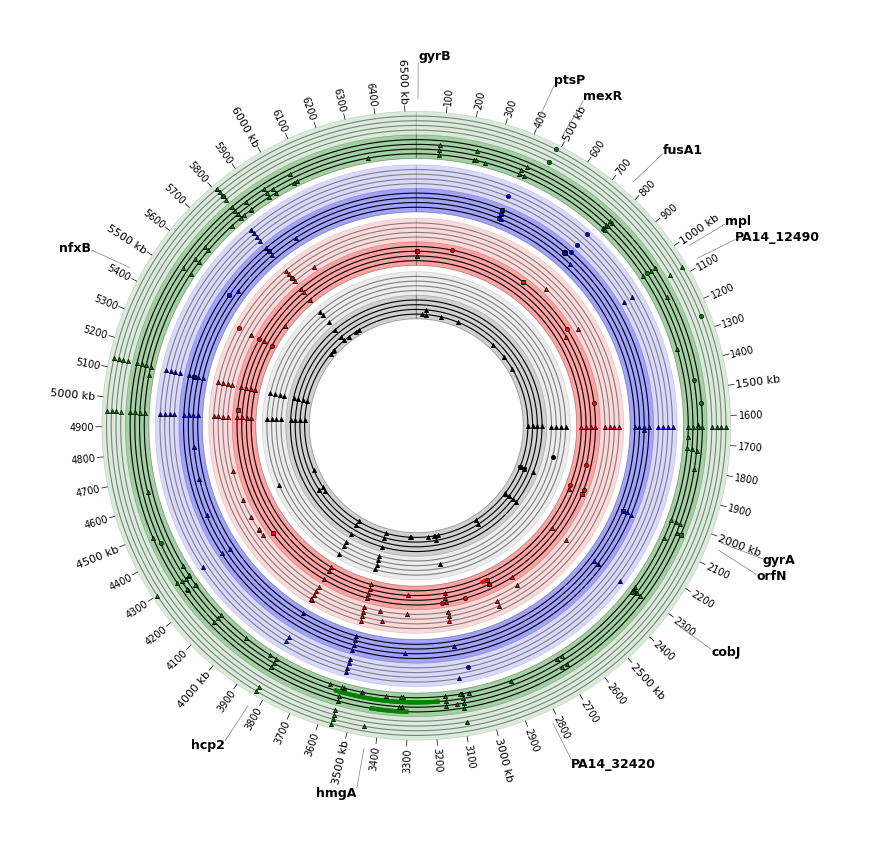

In [23]:
# Initialize Circos plot
circos = Circos(sectors= {'genome': genome_length})
sector = circos.sectors[0]
pip_track = sector.add_track((85, 100))#\.axis(fc="green", alpha=0.2)
tob_track = sector.add_track((68, 83))#.axis(fc="blue", alpha=0.2)
cip_track = sector.add_track((51, 66))#.axis(fc="red", alpha=0.2)
control_track = sector.add_track((34, 49))#.axis(fc="gray", alpha=0.2)

pip2_track = sector.add_track((85, 92.5))#\.axis(fc="green", alpha=0.2)

tob2_track = sector.add_track((68, 75.5))#.axis(fc="blue", alpha=0.2)

cip2_track = sector.add_track((51, 58.5))#.axis(fc="red", alpha=0.2)

control2_track = sector.add_track((34, 41.5))#.axis(fc="gray", alpha=0.1)

small_labels = [str(i) for i in range(100, 6600, 100) if i % 500 != 0]
small_locations = [i for i in range(100000, 6600000, 100000) if i % 500000 != 0]
pip_track.xticks(small_locations, small_labels, label_orientation="vertical", label_size=7)

large_labels = [str(i)+' kb' for i in range(500, 6600, 500) ]
large_locations = [i for i in range(500000, 6600000, 500000)]
pip_track.xticks(large_locations, large_labels, label_orientation="vertical", label_size=8)

gene_map = parse_gbk_for_genes(gbk_file)

#pip
circos.line(r=86.5, color="black",  lw = .8)
circos.line(r=88, color="black",  lw = .8)
circos.line(r=89.5, color="black",  lw = .8)
circos.line(r=91, color="black",  lw = .8)
circos.line(r=94, color="gray",  lw = .8)
circos.line(r=95.5, color="gray",  lw = .8)
circos.line(r=97, color="gray",  lw = .8)
circos.line(r=98.5, color="gray",  lw = .8)

#circos.text("4", r=86.5, size = 4)
#circos.text("1", r=88, size = 4)
#circos.text("1", r=89.5, size = 4)
#circos.text("4", r=91, size = 4)
#circos.text("1024", r=94, size = 4)
#circos.text("1024", r=95.5, size = 4)
#circos.text("1024", r=97, size = 4)
#circos.text("2048", r=98.5, size = 4)
#cip
circos.line(r=69.5, color="black",  lw = .8)
circos.line(r=71, color="black",  lw = .8)
circos.line(r=72.5, color="black",  lw = .8)
circos.line(r=74, color="black",  lw = .8)
circos.line(r=77, color="gray",  lw = .8)
circos.line(r=78.5, color="gray",  lw = .8)
circos.line(r=80, color="gray",  lw = .8)
circos.line(r=81.5, color="gray",  lw = .8)
#tob
circos.line(r=52.5, color="black",  lw = .8)
circos.line(r=54, color="black",  lw = .8)
circos.line(r=55.5, color="black",  lw = .8)
circos.line(r=57, color="black",  lw = .8)

circos.line(r=60, color="gray",  lw = .8)
circos.line(r=61.5, color="gray",  lw = .8)
circos.line(r=63, color="gray",  lw = .8)
circos.line(r=64.5, color="gray",  lw = .8)
#control
circos.line(r=35.5, color="black",  lw = .8)
circos.line(r=37, color="black",  lw = .8)
circos.line(r=38.5, color="black",  lw = .8)
circos.line(r=40, color="black",  lw = .8)
circos.line(r=43, color="gray",  lw = .8)
circos.line(r=44.5, color="gray",  lw = .8)
circos.line(r=46, color="gray",  lw = .8)
circos.line(r=47.5, color="gray",  lw = .8)

tob_track.axis(fc="blue", alpha=0.15)
pip_track.axis(fc="green", alpha=0.15)

cip_track.axis(fc="red", alpha=0.15)
control_track.axis(fc="gray", alpha=0.15)

tob2_track.axis(fc="blue", alpha=0.25)
pip2_track.axis(fc="green", alpha=0.25)
cip2_track.axis(fc="red", alpha=0.25)
control2_track.axis(fc="gray", alpha=0.25)

all_snps = []
for gd_file in os.listdir(gd_dir):
    if gd_file.endswith(".gd") and not gd_file.startswith('ANCESTOR'):
        file_path = os.path.join(gd_dir, gd_file)
        snps, deletions, insertions = parse_gd_file(file_path)
        print(gd_file)
        
        radius = radius_map[gd_file]
        snp_gene_matches = label_mutations(snps, [], gene_map)
        all_snps = list(set(all_snps + snp_gene_matches))
        
        # Helper to extract scalar positions if insertions contain tuples/lists
        def get_positions(items):
            positions = []
            for item in items:
                if isinstance(item, (list, tuple)):
                    positions.append(item[0]) # Take the start coordinate of the insertion
                else:
                    positions.append(item)
            return positions

        insertion_coords = get_positions(insertions)
        
        # --- TOBAMYCIN (T) ---
        if gd_file[3] == 'T':
            y = radius - 68
            if len(snps) != 0:
                tob_track.scatter(snps, np.full(len(snps), y), color="blue", vmax=15, vmin=0, marker='o', edgecolors='black', lw=.5)
            if len(insertion_coords) != 0:
                tob_track.scatter(insertion_coords, np.full(len(insertion_coords), y), color="blue", vmax=15, vmin=0, marker='s', edgecolors='black', lw=.5)
            if len(deletions) != 0:
                for d in deletions:
                    if (d[1] - d[0]) < 10000:
                        tob_track.scatter(np.arange(d[0], d[1], 10000), np.full(len(np.arange(d[0], d[1], 10000)), y), color="blue", vmax=15, vmin=0, marker='^', edgecolors='black', lw=.5)
                    else: 
                        circos.line(r=radius, deg_lim=(d[0]/genome_length*360, d[1]/genome_length*360), color='blue', lw=3)
                        
        # --- PIPERACILLIN (P) ---
        if gd_file[3] == 'P':
            y = radius - 85
            if len(snps) != 0:
                pip_track.scatter(snps, np.full(len(snps), y), color="green", vmax=15, vmin=0, marker='o', edgecolors='black', lw=.5)
            if len(insertion_coords) != 0:
                pip_track.scatter(insertion_coords, np.full(len(insertion_coords), y), color="green", vmax=15, vmin=0, marker='s', edgecolors='black', lw=.5)
            if len(deletions) != 0:
                for d in deletions: 
                    if (d[1] - d[0]) < 10000:
                        pip_track.scatter(np.arange(d[0], d[1], 10000), np.full(len(np.arange(d[0], d[1], 10000)), y), color="green", vmax=15, vmin=0, marker='^', edgecolors='black', lw=.5)
                    else: 
                        circos.line(r=radius, deg_lim=(d[0]/genome_length*360, d[1]/genome_length*360), color='green', lw=3) 
                        
        # --- CIPROFLOXACIN (C) ---
        if gd_file[3] == 'C':
            y = radius - 51
            if len(snps) != 0:
                cip_track.scatter(snps, np.full(len(snps), y), color="red", vmax=15, vmin=0, marker='o', edgecolors='black', lw=.5)
            if len(insertion_coords) != 0:
                cip_track.scatter(insertion_coords, np.full(len(insertion_coords), y), color="red", vmax=15, vmin=0, marker='s', edgecolors='black', lw=.5)
            if len(deletions) != 0:
                for d in deletions:
                    if (d[1] - d[0]) < 10000:
                        cip_track.scatter(np.arange(d[0], d[1], 10000), np.full(len(np.arange(d[0], d[1], 10000)), y), color="red", vmax=15, vmin=0, marker='^', edgecolors='black', lw=.5)
                    else: 
                        circos.line(r=radius, deg_lim=(d[0]/genome_length*360, d[1]/genome_length*360), color='red', lw=3)
                
        # --- CONTROL (N) ---
        if gd_file[3] == 'N':
            y = radius - 34
            if len(snps) != 0:
                control_track.scatter(snps, np.full(len(snps), y), color="black", vmax=15, vmin=0, marker='o', edgecolors='black', lw=.5)
            if len(insertion_coords) != 0:
                control_track.scatter(insertion_coords, np.full(len(insertion_coords), y), color="black", vmax=15, vmin=0, marker='s', edgecolors='black', lw=.5)
            if len(deletions) != 0:
                for d in deletions:
                    if (d[1] - d[0]) < 10000:
                        control_track.scatter(np.arange(d[0], d[1], 10000), np.full(len(np.arange(d[0], d[1], 10000)), y), color="black", vmax=15, vmin=0,marker ='^', edgecolors='black', lw=.5)
                    else: 
                        circos.line(r=radius, deg_lim=(d[0]/genome_length*360, d[1]/genome_length*360), color='black', lw=3)

target_genes = {
    "hmgA", "mpl", "hcp2", "mexR", 
    "PA14_12490", "gyrA", "gyrB", "PA14_32420", 
    "nfxB", "fusA1", "cobJ", "orfN", "ptsP"
}

for start, end, gene_name in gene_map:
    if gene_name in target_genes:
        # Calculate the midpoint of the gene
        label_pos = (start + end) / 2
        
        # Call annotate directly on pip_track (the outer track)
        pip_track.annotate(
            label_pos,
            gene_name,
            label_size = 9,
            min_r=104,            # Minimum radius for the leader line
            max_r=118,            # Pushes the outer label text further out
            text_kws=dict(fontweight="bold")  # Makes the text bold
        )
        print(f"Annotated '{gene_name}' at coordinate {label_pos}")

fig = circos.plotfig()

line_handles = [
    Line2D([], [], color="gray", label="Anaerobic"),
    Line2D([], [], color="black", label="Aerobic")]


line_legend = circos.ax.legend(
    handles=line_handles,
    bbox_to_anchor=(0.93, 1.12),
    fontsize=8,
    title="Oxygen",
    handlelength=2,
)
circos.ax.add_artist(line_legend)

rect_handles = [
    Patch(color='green', label="Piperacillin", alpha= 0.2),
    Patch(color='blue', label="Tobramycin", alpha= 0.2),
    Patch(color='red', label="Ciprofloxacin", alpha= 0.2),
    Patch(color='gray', label="Control", alpha= 0.2)
]

rect_legend = circos.ax.legend(
    handles=rect_handles,
    bbox_to_anchor=(0.93, 1.03),
    fontsize=8,
    title="Drugs",
    handlelength=2
)
circos.ax.add_artist(rect_legend)
fig = circos.plotfig()

output_filename = "aerobic_anaerobic_mutations.png"
fig.savefig(output_filename, dpi=300, bbox_inches="tight")
print(f"\nPlot successfully saved as '{output_filename}' at 300 DPI!")

In [ ]:
import os
import pandas as pd
from Bio import SeqIO

# 3. Helper to match mutation positions to features from the GenBank file
def annotate_mutation_key(mut_string, gene_map):
    """
    Takes a mutation string like 'SNP_12345' and maps it to a gene name/locus tag.
    """
    parts = mut_string.split("_")
    pos = int(parts[1]) # Extract coordinate
    
    matched_label = "Intergenic"
    for start, end, gene_name in gene_map:
        if start <= pos <= end:
            matched_label = gene_name
            break
            
    return f"{mut_string} ({matched_label})"


# 4. Matrix Generation Function
def create_annotated_mutation_matrix(gd_directory, gbk_file, output_excel="mutation_matrix_annotated.xlsx"):
    """
    Scans .gd files, maps them against GenBank features for gene/locus tag annotations,
    and exports an Excel sheet with binary presence/absence (1/0).
    """
    print("Parsing GenBank file for gene annotations...")
    gene_map = parse_gbk_for_genes(gbk_file)
    
    sample_data = {}
    all_mutations = set()
    
    gd_files = [f for f in os.listdir(gd_directory) if f.endswith(".gd")]
    
    if not gd_files:
        print(f"No .gd files found in: {gd_directory}")
        return

    print(f"Parsing {len(gd_files)} .gd files...")
    for filename in gd_files:
        sample_name = os.path.splitext(filename)[0]
        file_path = os.path.join(gd_directory, filename)
        
        snps, deletions, insertions = parse_gd_file(file_path)
        
        sample_muts = set()
        for s in snps:
            sample_muts.add(f"SNP_{s}")
        for d_start, d_end in deletions:
            sample_muts.add(f"DEL_{d_start}_{d_end}")
        for i_start, i_size in insertions:
            sample_muts.add(f"INS_{i_start}_{i_size}")
            
        sample_data[sample_name] = sample_muts
        all_mutations.update(sample_muts)

    # Sort mutations logically by coordinate
    sorted_mutations = sorted(list(all_mutations), key=lambda x: int(x.split("_")[1]))
    
    # Annotate column headers with Gene Name / Locus Tag
    annotated_headers = [annotate_mutation_key(m, gene_map) for m in sorted_mutations]

    # Build binary matrix rows
    matrix_rows = []
    sample_names = []
    
    for sample_name, muts in sample_data.items():
        sample_names.append(sample_name)
        row = [1 if m in muts else 0 for m in sorted_mutations]
        matrix_rows.append(row)

    # Create DataFrame and export to Excel
    df = pd.DataFrame(matrix_rows, index=sample_names, columns=annotated_headers)
    df.index.name = "Sample_Name"
    
    output_path = os.path.join(gd_directory, output_excel)
    df.to_excel(output_path)
    
    print(f"\nSuccessfully created annotated matrix: '{output_path}'")
    print(f"Dimensions: {df.shape[0]} samples x {df.shape[1]} mutations.")
    return df

In [32]:
# Run the function to generate and save the Excel sheet
create_annotated_mutation_matrix(gd_directory=gd_dir, gbk_file=gbk_file, output_excel="annotated_mutation_matrix.xlsx")

Parsing GenBank file for gene annotations...
Parsing 32 .gd files...

Successfully created annotated matrix: 'C:/Users/jmf7ak/OneDrive - University of Virginia/25_SPRING/Evolution_paper/subtracted_gd_trimmed_fastp\annotated_mutation_matrix.xlsx'
Dimensions: 32 samples x 436 mutations.


,DEL_5463_5475 (gyrB),DEL_5463_5474 (gyrB),INS_5649_3 (gyrB),DEL_49680_49902 (PA14_00510),DEL_86385_86927 (ppkA),DEL_86500_86929 (ppkA),DEL_86550_86927 (ppkA),DEL_86586_86927 (ppkA),DEL_86626_86927 (ppkA),SNP_209027 (PA14_02330),...,DEL_5944032_5944271 (PA14_66580),DEL_5944051_5944272 (PA14_66580),DEL_5944056_5944234 (PA14_66580),DEL_5944100_5944330 (PA14_66580),DEL_5972086_5972564 (PA14_66850),DEL_5972091_5972563 (PA14_66850),DEL_5972154_5972502 (phaF),DEL_6053809_6053995 (PA14_67790),DEL_6064137_6064334 (PA14_67940),DEL_6353631_6353781 (PA14_71300)
Sample_Name,,,,,,,,,,,,,,,,,,,,,
AE_C1_S21_subtracted,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AE_C2_S22_subtracted,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AE_C3_S23_subtracted,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AE_C6_S24_subtracted,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
AE_N1_S25_subtracted,0,0,0,1,0,0,1,0,0,0,...,0,1,0,0,0,1,0,0,0,0
AE_N2_S26_subtracted,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
AE_N3_S27_subtracted,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AE_N4_S28_subtracted,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
AE_P1_S13_subtracted,0,0,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,1,1,1,1
